# 04 · Observing realities

**Level:** intermediate · **Prerequisites:** [01](01_first_light_curve.ipynb), [03](03_first_fit.ipynb) · **Run time:** ~20 s

**Covers:** long exposures (`supersample_factor`, `exp_time`), eccentric orbits and the timing helpers, secondary eclipses (`transittype`, `fp`, `t_secondary`), grazing transits, inverse transits, `calc_err`, `series_cut`

Real light curves are integrated over exposures, orbits are eccentric, planets are eclipsed, and some transits only graze the star. All of this works exactly as in batman.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pizzetti

def make_params(**kw):
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp, p.a, p.inc, p.ecc, p.w = 0.0, 10.0, 0.05, 20.0, 89.5, 0.0, 90.0
    p.limb_dark, p.u = "quadratic", [0.4, 0.25]
    for k, v in kw.items():
        setattr(p, k, v)
    return p

## 1. Long exposures

Kepler's long cadence integrates for 29.4 minutes. A model evaluated only at the mid-exposure times
is too sharp at ingress and egress; `supersample_factor` averages the model over that many points
spread across `exp_time` (same unit as `t`).

largest difference: 194 ppm


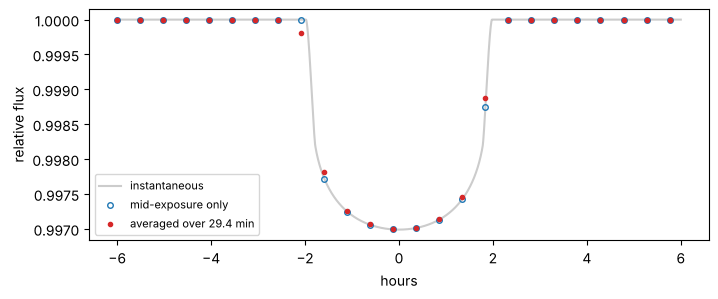

In [2]:
p = make_params()
t = np.arange(-0.25, 0.25, 29.4 / 1440)                       # long-cadence time stamps
fine = np.linspace(-0.25, 0.25, 4000)
m_point = pizzetti.TransitModel(p, t)
m_avg = pizzetti.TransitModel(p, t, supersample_factor=15, exp_time=29.4 / 1440)
plt.figure(figsize=(8, 3))
plt.plot(24 * fine, pizzetti.TransitModel(p, fine).light_curve(p), color="0.8", label="instantaneous")
plt.plot(24 * t, m_point.light_curve(p), "o", ms=4, mfc="none", label="mid-exposure only")
plt.plot(24 * t, m_avg.light_curve(p), "C3.", label="averaged over 29.4 min")
plt.xlabel("hours"); plt.ylabel("relative flux"); plt.legend(fontsize=8)
print(f"largest difference: {1e6 * np.max(np.abs(m_avg.light_curve(p) - m_point.light_curve(p))):.0f} ppm")

## 2. Eccentric orbits

`ecc` and `w` (argument of periastron, degrees) change the speed of the planet during transit and
therefore the duration. The timing helpers return the times of periastron, secondary eclipse and
conjunction, and the true anomaly at every time stamp.

e = 0.0, w =  90.0: periastron at   0.000 d, secondary eclipse at  5.000 d, true anomaly at t = 0: 0.0°
e = 0.4, w =  90.0: periastron at   0.000 d, secondary eclipse at  5.000 d, true anomaly at t = 0: 0.0°
e = 0.4, w =  45.0: periastron at  -0.521 d, secondary eclipse at -3.150 d, true anomaly at t = 0: 45.0°
e = 0.4, w = 270.0: periastron at   5.000 d, secondary eclipse at  5.000 d, true anomaly at t = 0: -180.0°


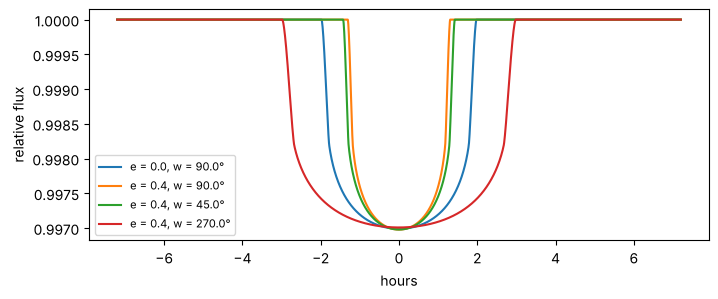

In [3]:
t = np.linspace(-0.3, 0.3, 3000)
plt.figure(figsize=(8, 3))
for ecc, w in [(0.0, 90.0), (0.4, 90.0), (0.4, 45.0), (0.4, 270.0)]:
    p = make_params(ecc=ecc, w=w)
    m = pizzetti.TransitModel(p, t)
    plt.plot(24 * t, m.light_curve(p), label=f"e = {ecc}, w = {w}°")
    print(f"e = {ecc}, w = {w:5.1f}: periastron at {m.get_t_periastron(p):7.3f} d, "
          f"secondary eclipse at {m.get_t_secondary(p):6.3f} d, true anomaly at t = 0: {np.degrees(m.get_true_anomaly()[t.size // 2]):.1f}°")
plt.xlabel("hours"); plt.ylabel("relative flux"); plt.legend(fontsize=8);

At w = 90° the planet transits at periastron (fastest, shortest transit), at w = 270° at apastron (slowest, longest); w = 45° lies in between.

## 3. Secondary eclipses

With `transittype="secondary"` the model is the planet's light being blocked by the star: the flux is
1 + `fp` outside the eclipse and 1 during it. `t_secondary` is the time of mid-eclipse (for a circular
orbit half a period after `t0`).

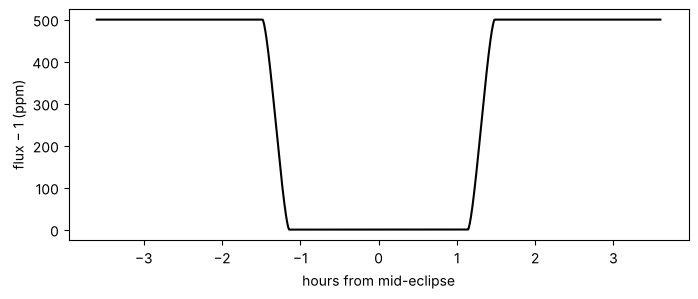

In [4]:
p = make_params(rp=0.1, a=9.0, per=3.5, inc=87.0, fp=500e-6, t_secondary=1.75)
t = np.linspace(1.6, 1.9, 2000)
m = pizzetti.TransitModel(p, t, transittype="secondary")
plt.figure(figsize=(8, 3)); plt.plot(24 * (t - 1.75), 1e6 * (m.light_curve(p) - 1), "k")
plt.xlabel("hours from mid-eclipse"); plt.ylabel("flux − 1 (ppm)");

## 4. Grazing transits

When the impact parameter exceeds 1 − rp, the planet never lies entirely inside the stellar disk: the
transit is V-shaped and every sample is on the limb. pizzetti's interior series then never applies, and
the limb methods (notebook 07) do all the work; the accuracy is unchanged.

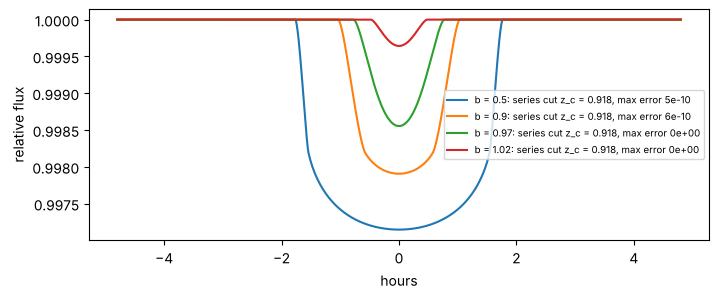

In [5]:
t = np.linspace(-0.2, 0.2, 2000)
plt.figure(figsize=(8, 3))
for b in (0.5, 0.9, 0.97, 1.02):
    p = make_params(rp=0.05, inc=np.degrees(np.arccos(b / 20.0)))
    m = pizzetti.TransitModel(p, t)
    ref = pizzetti.TransitModel(p, t, series_tol=0.0, limb="quadrature").light_curve(p)
    f = m.light_curve(p)
    plt.plot(24 * t, f, label=f"b = {b}: series cut z_c = {m.series_cut(p):.3f}, max error {np.max(np.abs(f - ref)):.0e}")
plt.xlabel("hours"); plt.ylabel("relative flux"); plt.legend(fontsize=7);

`m.series_cut(p)` is the separation z_c up to which the interior series is used (with its error proven
below `series_tol`). For b > z_c no sample uses it.

## 5. Inverse transits

As in batman, a negative `rp` flips the sign of the transit signal (useful e.g. for modelling a bright
spot, or for testing).

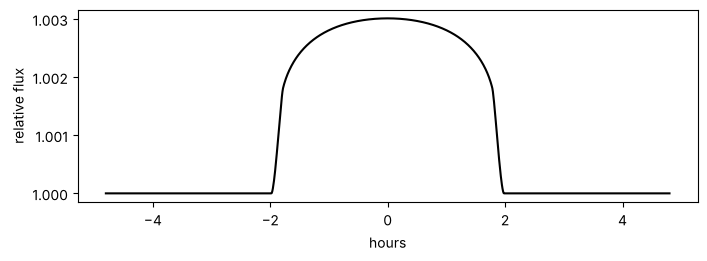

In [6]:
p = make_params(rp=-0.05)
t = np.linspace(-0.2, 0.2, 1000)
plt.figure(figsize=(8, 2.5)); plt.plot(24 * t, pizzetti.TransitModel(p, t).light_curve(p), "k")
plt.xlabel("hours"); plt.ylabel("relative flux");

## 6. How accurate is my model? `calc_err`

batman's `calc_err` reports the largest flux error in ppm. pizzetti's version compares the model with
its quadrature reference on a grid of separations; it never reports less than `series_tol`, the proven
bound of the interior series.

In [7]:
for law, u in [("quadratic", [0.4, 0.25]), ("power2", [0.7, 0.6]), ("nonlinear", [0.5, 0.1, 0.1, -0.1])]:
    p = make_params(limb_dark=law, u=u)
    m = pizzetti.TransitModel(p, np.linspace(-0.2, 0.2, 100))
    print(f"{law:10s} calc_err = {m.calc_err():.1e} ppm")

quadratic  calc_err = 1.0e-03 ppm
power2     calc_err = 1.0e-03 ppm
nonlinear  calc_err = 1.0e-03 ppm


## What you learned

- Long exposures: `supersample_factor` and `exp_time`.
- Eccentric orbits change the duration; `get_t_periastron`, `get_t_secondary`, `get_t_conjunction`, `get_true_anomaly` give the timing.
- `transittype="secondary"` with `fp` and `t_secondary` models eclipses; negative `rp` gives inverse transits.
- Grazing transits skip the interior series but keep the accuracy; `series_cut` and `calc_err` tell you what is used and how accurate it is.

**Next:** [05 · Choosing a limb-darkening law](05_choosing_a_limb_darkening_law.ipynb)